


# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

 Ideia aqui é pegar as primeira informações, como tipo de dados e valores ausentes, de cada DF para iniciar o tratamento de dados

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
# Importe as bibliotecas

In [ ]:
instacart_orders = pd.read_csv('/datasets/instacart_orders.csv',sep = ';')# leia os conjuntos de dados em DataFrames

print(instacart_orders.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None


In [ ]:
products = pd.read_csv('/datasets/products.csv',sep = ';')

print(products.info(show_counts= True))
# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None


In [ ]:
order_products = pd.read_csv('/datasets/order_products.csv',sep = ';')

print(order_products.info(show_counts= True))# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None


In [ ]:
aisles = pd.read_csv('/datasets/aisles.csv',sep = ';')

print(aisles.info())# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None


In [ ]:
departments = pd.read_csv('/datasets/departments.csv',sep = ';')

print(departments.info())# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes
None


## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 1. Visão geral dos dados
 DF instacart_orders -  percebemos as 5 primeiras colunas com valores inteiros e a última com valores flutuantes e com numeros ausentes, que precisará ser corrigoda
 DF products - percebemos a segunda coluna com valores ausentes, que precisará ser corrigida, e com o tiop object, enquanto as outras estão completas com tipo inteiro
 DF orders_product - Temos a terceira coluna com valores ausentes, que precisará ser corrigida, e com o tipo float, enquanto o restante está completa com o tipo int
 DF aisles - as 2 colunas estão completas uma com tipo object e a outra int, só para indicar o nome e o código do corredor
 DF departaments - as 2 colunas completas uma com tipo object e a outra int, só para indicar o nome e o código do departamento

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

Escreva aqui seu plano para a Etapa 2. Preparação de dados

Aqui vamos verificar duplicatas de linha completa, duplicatas baseadas em subconjunto e verificações de valores ausentes por coluna.

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [ ]:
print(instacart_orders.duplicated().sum())
print()
print(instacart_orders[instacart_orders.duplicated()])# Verificar se há pedidos duplicados

15

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
145574    794638    50898            24          3                  2   
223105   2160484   107525            16          3                  2   
230807   1918001   188546            14          3                  2   
266232   1782114   106752             1          3                  2   
273805   1112182   202304            84          3                  2   
284038   2845099    31189            11          3                  2   
311713   1021560    53767             3          3                  2   
321100    408114    68324             4          3                  2   
323900   1919531   191501            32          3                  2   
345917   2232988    82565             1          3                  2   
371905    391768    57671            19          3                  2   
394347    467134    63189            21          3                  2   
411408   1286742   183220            48        

Há linhas duplicadas? Se sim, o que elas têm em comum? Existe linhas duplicadas e todas foram pedidos feitos as 2h e na quarta feira

In [ ]:
wednesday_2am = instacart_orders.query(('order_hour_of_day==2 and order_dow == 3'))

print(wednesday_2am)# Com base nas suas conclusões,

print(wednesday_2am[wednesday_2am.duplicated()])
# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

O que esse resultado quer dizer? temos 121 pedidos de quarta feira as 2h e 15 duplicados, me parece problema de sistema, podemos excluir

In [ ]:
instacart_orders = instacart_orders.drop_duplicates()# Remova pedidos duplicados

In [ ]:
print(instacart_orders.duplicated().sum())# Verifique as linhas duplicadas mais uma vez

0


In [ ]:
print(wednesday_2am['user_id'][wednesday_2am.duplicated()])# Verifique novamente apenas os IDs de pedidos duplicados

145574     50898
223105    107525
230807    188546
266232    106752
273805    202304
284038     31189
311713     53767
321100     68324
323900    191501
345917     82565
371905     57671
394347     63189
411408    183220
415163     86751
441599     14050
Name: user_id, dtype: int64


Descreva brevemente suas conclusões e o que você fez com elas.

Indentificamos pedidos duplicados no DF, esses pedidos paraceiam ser problema de sistema, por isso apenas excluimos da análise.

### DataFrame `products`

In [ ]:
print(products.duplicated().sum())# Verifique se há linhas completamente duplicadas

0


In [ ]:
print(products[products['product_id'].duplicated()])# Verifique apenas IDs dos produtos duplicados

Empty DataFrame
Columns: [product_id, product_name, aisle_id, department_id]
Index: []


In [ ]:
# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)
products_lower_name = products['product_name'].str.lower()
print(products_lower_name[products_lower_name.duplicated()])

71                                                   NaN
109                                                  NaN
296                                                  NaN
416                                                  NaN
436                                                  NaN
                              ...                       
49689                      high performance energy drink
49690                      original pancake & waffle mix
49691    organic instant oatmeal light maple brown sugar
49692                             spring water body wash
49693                            burrito- steak & cheese
Name: product_name, Length: 1361, dtype: object


In [ ]:
products_lower_name = products_lower_name[products_lower_name.notna()]
nomes_repetidos = products_lower_name[products_lower_name.duplicated()]
print(products_lower_name)
print()
print(products_lower_name.duplicated().sum())
print()
print(products[products['product_name'].str.lower().isin(nomes_repetidos)].sort_values('product_name'))
# Verifique os nomes de produtos duplicados que não estão faltando

0                               chocolate sandwich cookies
1                                         all-seasons salt
2                     robust golden unsweetened oolong tea
3        smart ones classic favorites mini rigatoni wit...
4                                green chile anytime sauce
                               ...                        
49689                        high performance energy drink
49690                        original pancake & waffle mix
49691      organic instant oatmeal light maple brown sugar
49692                               spring water body wash
49693                              burrito- steak & cheese
Name: product_name, Length: 48436, dtype: object

104

       product_id                               product_name  aisle_id  \
31844       31845  18-In-1 Hemp Peppermint Pure-Castile Soap        25   
23339       23340  18-in-1 Hemp Peppermint Pure-Castile Soap        25   
19941       19942            Aged Balsamic Vinegar Of Modena        19   


Descreva brevemente suas conclusões e o que você fez com elas.

Observamos que tinhas produtos duplicados escritos com letras maiúsculas e minusculas, que são os mesmos produtos, com departamento e corredores iguais.Pedidos com  NaN, preenchemos com 'Unknown'

### DataFrame `departments`

In [ ]:
print(departments.duplicated().sum())# Verifique se há linhas completamente duplicadas

0


In [ ]:
print(departments[departments['department'].duplicated()])# Verifique apenas IDs duplicados de departamentos

Empty DataFrame
Columns: [department_id, department]
Index: []


Descreva brevemente suas conclusões e o que você fez com elas

Sem departamentos duplicados


### DataFrame `aisles`

In [ ]:
print(aisles.duplicated().sum())# Verifique se há linhas completamente duplicadas

0


In [ ]:
print(aisles[aisles['aisle'].duplicated()])# Verifique apenas IDs duplicados de corredores

Empty DataFrame
Columns: [aisle_id, aisle]
Index: []


Descreva brevemente suas conclusões e o que você fez com elas.

Sem corredores dupllicados

### DataFrame `order_products`

In [ ]:
# Verifique se há linhas completamente duplicadas
print(order_products.duplicated().sum())

0


In [ ]:
# Verifique mais uma vez se há outros casos complicados de duplicados

print(order_products.duplicated(subset=['order_id','product_id']).sum())

0


Descreva brevemente suas conclusões e o que você fez com elas.

Não idendificamos nenhum dado duplicado nod DFs order_products.

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [ ]:
# Encontre valores ausentes na coluna 'product_name'

print(products[products['product_name'].isna()])


       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]


Descreva brevemente suas conclusões.

Temos 1258 valores ausentes na coluna product_name

In [ ]:
# Todos os nomes de produtos ausentes estão associados com o corredor de ID 100?

products_na = products[products['product_name'].isna()]

print(products_na['aisle_id'].unique())

[100]


Descreva brevemente suas conclusões.

Todas as linhas estão no corredor 100

In [ ]:
# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?

products_na = products[products['product_name'].isna()]

print(products_na['department_id'].unique())

[21]


Descreva brevemente suas conclusões.

Todas as linhas estão no departamento 21

In [ ]:
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.

print(departments.query('department_id == 21'))
print()
print(aisles.query('aisle_id ==100'))

    department_id department
20             21    missing

    aisle_id    aisle
99       100  missing


Descreva brevemente suas conclusões.

o departamento 21 e corredor 100 são utilizados para produtos faltantes

In [ ]:
# Preencha nomes de produtos ausentes com 'Unknown'
products['product_name'] = products['product_name'].fillna('Unknown')


Descreva brevemente suas conclusões e o que você fez com elas.

Os valores ausentes descobertos aqui são de departamento e corredor de produtos faltantes, preenchemos com 'Unknown', para não excluir linhas que impactariam nos dados

### DataFrame `orders`

In [ ]:
print(instacart_orders[instacart_orders['days_since_prior_order'].isna()])# Encontre os valores ausentes

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
28        133707   182261             1          3                 10   
96        787445    25685             1          6                 18   
100       294410   111449             1          0                 19   
103      2869915   123958             1          4                 16   
104      2521921    42286             1          3                 18   
...          ...      ...           ...        ...                ...   
478895   2589657   205028             1          0                 16   
478896   2222353   141211             1          2                 13   
478922   2272807   204154             1          1                 15   
478926   2499542    68810             1          4                 19   
478945   1387033    22496             1          5                 14   

        days_since_prior_order  
28                         NaN  
96                         NaN  
100                     

In [ ]:
# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?

instacart_orders_teste = instacart_orders[instacart_orders['days_since_prior_order'].isna()]

print(instacart_orders_teste.query('order_number != 1'))

Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


Descreva brevemente suas conclusões e o que você fez com elas.

Os valores ausesntes na coluna 'days_since_prior_order', são porque aqueles são os primeiros pedidos dos clientes, não podeira tem nenhuma informação nessa coluna, já que são os primeiros pedidos. Por isso, mantemos a coluna.

### DataFrame `order_products`

In [ ]:
# Encontre os valores ausentes
order_products_nan = order_products[order_products['add_to_cart_order'].isna()]
print(order_products_nan)

         order_id  product_id  add_to_cart_order  reordered
737       2449164        5068                NaN          0
9926      1968313       43867                NaN          0
14394     2926893       11688                NaN          0
16418     1717990        4142                NaN          0
30114     1959075       42828                NaN          1
...           ...         ...                ...        ...
4505662   1800005        7411                NaN          0
4511400   1633337         260                NaN          0
4517562    404157        9517                NaN          0
4534112   1673227       17835                NaN          0
4535739   1832957       17949                NaN          1

[836 rows x 4 columns]


In [ ]:
# Quais são os valores mínimo e máximo dessa coluna?

print(order_products['add_to_cart_order'].min())

print(order_products['add_to_cart_order'].max())

1.0
64.0


Descreva brevemente suas conclusões.
Vimos que o mínimo de itens no carrinho é 1 e o  maximo de itens adicionados no carrinho 64.

In [ ]:
# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'
order_id_nan_unique = order_products_nan['order_id'].unique()
print(len(order_id_nan_unique))

70


In [ ]:
# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
# Agrupe os pedidos com dados ausentes por ID de pedido
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem
order_products_filtred_nan = order_products[order_products['order_id'].isin(order_id_nan_unique)]


order_products_filtred_nan_group = order_products_filtred_nan.groupby('order_id').size()
print()
print(order_products_filtred_nan_group.min())




65


Descreva brevemente suas conclusões.

Todos as linhas que tem valores ausentes tem mais do que 64 produtos no pedido

In [ ]:
# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer


order_products['add_to_cart_order'] = order_products['add_to_cart_order'].fillna(999)

order_products['add_to_cart_order'] = order_products['add_to_cart_order'].astype('int')

print(order_products.query('add_to_cart_order == 999'))


         order_id  product_id  add_to_cart_order  reordered
737       2449164        5068                999          0
9926      1968313       43867                999          0
14394     2926893       11688                999          0
16418     1717990        4142                999          0
30114     1959075       42828                999          1
...           ...         ...                ...        ...
4505662   1800005        7411                999          0
4511400   1633337         260                999          0
4517562    404157        9517                999          0
4534112   1673227       17835                999          0
4535739   1832957       17949                999          1

[836 rows x 4 columns]


Descreva brevemente suas conclusões e o que você fez com elas.

vimos que o valor máximo em add_to_cart_order é 64, o que significa que nenhum item é adicionado numa posição maior que 64 no carrinho. Usamos o 999 para substituir os NaN para não ser confundido com uma posição real

## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 2. Preparação de dados

Na etapa 2 verificamos: 15 pedidos duplicados removidos (anomalia de quarta-feira às 2h), 1.258 nomes de produtos ausentes preenchidos com 'Unknown' (aisle 100/department 21), NaNs de days_since_prior_order mantidos como estão (primeiros pedidos), e 836 valores ausentes de add_to_cart_order preenchidos com 999.


# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:


# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [ ]:
print(sorted(instacart_orders['order_hour_of_day'].unique()))
print(sorted(instacart_orders['order_dow'].unique()))


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
[0, 1, 2, 3, 4, 5, 6]


In [ ]:

orders_id_day = instacart_orders.value_counts('order_dow')
print(orders_id_day)



order_dow
0    84090
1    82185
2    65833
5    63488
6    62649
3    60897
4    59810
dtype: int64


Escreva suas conclusões aqui
Os valores fazem sentido, 7 dias da semana e 24h no dia

### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

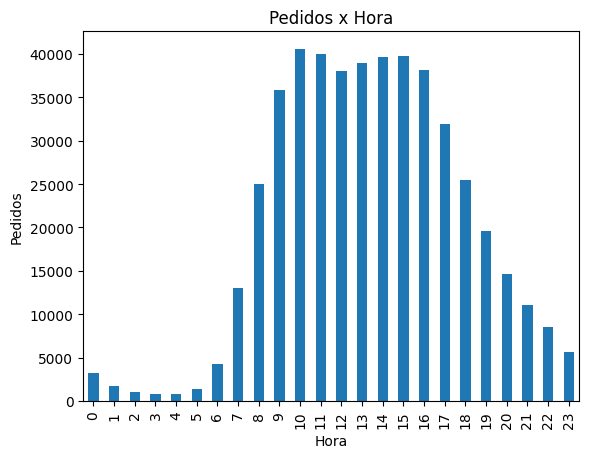

In [ ]:
orders_id_day = instacart_orders['order_hour_of_day'].value_counts().sort_index()

orders_id_day.plot(kind = 'bar',
                  title = 'Pedidos x Hora',
                  ylabel = 'Pedidos', xlabel = 'Hora')
plt.show()


Escreva suas conclusões aqui

Podemos obseravr que a maioria dos pedidos são feitos em horário comercial, começam a aumentar a partir das 7h e vão diminuindo após as 17h

### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

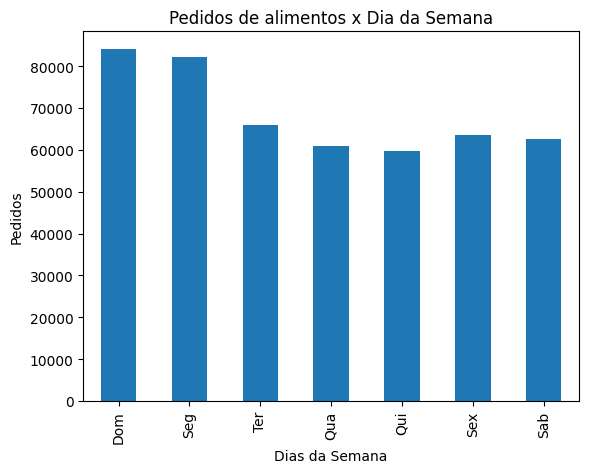

In [ ]:



order_dow_count = instacart_orders['order_dow'].value_counts().sort_index()
dow = ['Dom','Seg','Ter','Qua','Qui','Sex','Sab']
order_dow_count.index = dow
order_dow_count.plot(kind='bar',
                     title='Pedidos de alimentos x Dia da Semana',
                     xlabel='Dias da Semana',
                     ylabel='Pedidos')
plt.show()



Escreva suas conclusões aqui.

Não teve diferença significativa para compras totais e compra de produtos alimentícios

### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

Escreva suas conclusões aqui
O mínimo de 0 pode indicar que pessoas fazem comprar no mesmo dia em horarios diferentes, e o máximo de 30 pode incar que fazem compra mensal.
existem pessoas que fazem a segunda compra até no mesmo dia e essa frequancia aumenta até 7 ou 8 dias. Depois disso a frequencia diminui e depois tem um pico em 30 dias o que indica que muitas pessoas fazem compras mensais

0.0

30.0

11.101813900274362



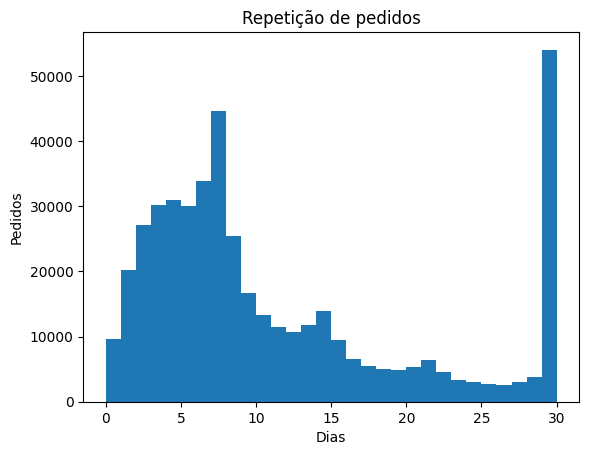

In [ ]:
print(instacart_orders['days_since_prior_order'].min())
print()
print(instacart_orders['days_since_prior_order'].max())
print()
print(instacart_orders['days_since_prior_order'].mean())
print()

import importlib
importlib.reload(plt)

instacart_orders['days_since_prior_order'].plot(kind = 'hist', bins=30,
                                               title = 'Repetição de pedidos')
plt.xlabel ('Dias')
plt.ylabel ('Pedidos')
plt.show()

# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

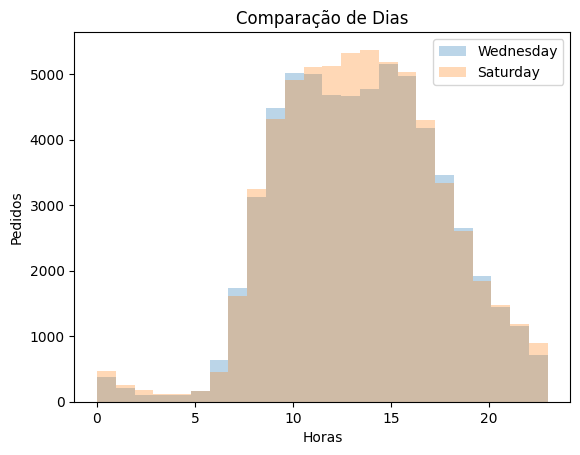

In [ ]:
order_wednesday = instacart_orders.query('order_dow == 3')
order_saturday = instacart_orders.query('order_dow == 6')

order_wednesday['order_hour_of_day'].plot(kind = 'hist', alpha = 0.3, bins = 24)
order_saturday['order_hour_of_day'].plot(kind = 'hist', alpha= 0.3, bins = 24)


plt.legend(['Wednesday', 'Saturday'])
plt.title('Comparação de Dias')
plt.xlabel('Horas')
plt.ylabel('Pedidos')
plt.show()

Escreva suas conclusões aqui.

Não tem muita diferença nos 2 gráficos, quarta e sabado a maioria das compras são em horario comercial. Existe uma leve queda no horario de almoça as quartas feiras

### [B2] Qual é a distribuição do número de pedidos por cliente?

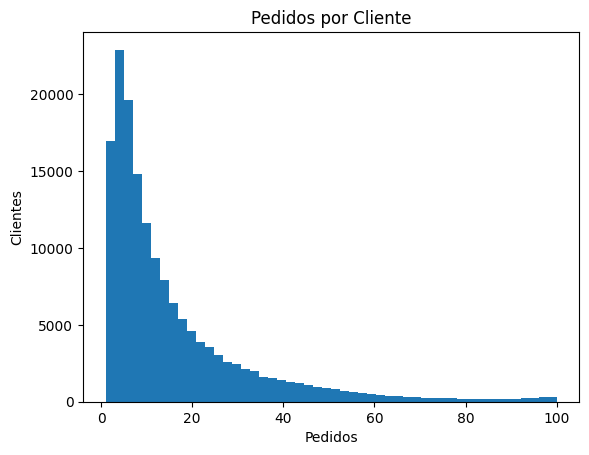

In [ ]:

order_by_client = instacart_orders.groupby('user_id')['order_number'].max()

order_by_client.plot(kind = 'hist', bins = 50,
                    title = 'Pedidos por Cliente')
plt.xlabel('Pedidos')
plt.ylabel('Clientes')
plt.show()



Escreva suas conclusões aqui.
Podemos observar a maioria dos cleintes entre 0 a 10 pedidos e a curva vai diminuindo a medida que os pedidos consecutivos aumentam. Podemos concluir que temos mais clientes ocasionais do que recorrentes

### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

In [ ]:
popular_products = order_products['product_id'].value_counts().reset_index()
popular_products.columns = ['product_id','quantidade']
print(popular_products.head(20))




    product_id  quantidade
0        24852       66050
1        13176       53297
2        21137       37039
3        21903       33971
4        47209       29773
5        47766       24689
6        47626       21495
7        16797       20018
8        26209       19690
9        27845       19600
10       27966       19197
11       22935       15898
12       24964       15292
13       45007       14584
14       39275       13879
15       49683       13675
16       28204       12544
17        5876       12232
18        8277       11993
19       40706       11781


In [ ]:
name_popular_products = popular_products.merge(products, on ='product_id')
print(name_popular_products[['product_id','product_name']].head(20))

    product_id              product_name
0        24852                    Banana
1        13176    Bag of Organic Bananas
2        21137      Organic Strawberries
3        21903      Organic Baby Spinach
4        47209      Organic Hass Avocado
5        47766           Organic Avocado
6        47626               Large Lemon
7        16797              Strawberries
8        26209                     Limes
9        27845        Organic Whole Milk
10       27966       Organic Raspberries
11       22935      Organic Yellow Onion
12       24964            Organic Garlic
13       45007          Organic Zucchini
14       39275       Organic Blueberries
15       49683            Cucumber Kirby
16       28204        Organic Fuji Apple
17        5876             Organic Lemon
18        8277  Apple Honeycrisp Organic
19       40706    Organic Grape Tomatoes


Escreva suas conclusões aqui.
Podemos concluir que os 20 produtos mais escolhidos estão relacionados a serem produtos , na sua maioria, organicos.

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

In [ ]:
count_products_per_order = order_products.groupby('order_id')['product_id'].count()
print(count_products_per_order.mean())
print()
print(count_products_per_order.min())
print()
print(count_products_per_order.max())
print()

10.098983215049127

1

127



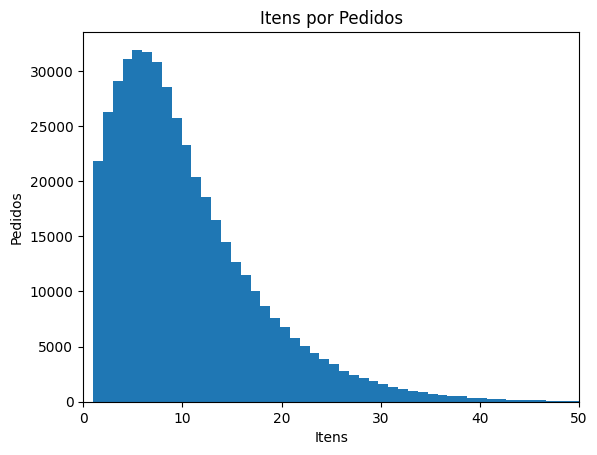

In [ ]:
count_products_per_order.plot(kind = 'hist', bins = 127,
                             xlim = (0,50),
                             title = 'Itens por Pedidos')

plt.xlabel ('Itens')
plt.ylabel ('Pedidos')

plt.show()


Escreva suas conclusões aqui.

Podemos notar uma média de 10,1 itens por pedido. A grande maioria fica entre 3 e 6  itens. A partir disso os itens por pedidos começam a cair e não temos quase nenhum pedido com mais de 40 itens

### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

In [ ]:

products_reordered = order_products.query('reordered == 1')
popular_products_reordered = products_reordered['product_id'].value_counts().reset_index()
popular_products_reordered.columns = ['product_id', 'quantidade']
print(popular_products_reordered)


       product_id  quantidade
0           24852       55763
1           13176       44450
2           21137       28639
3           21903       26233
4           47209       23629
...           ...         ...
36223        2591           1
36224       29201           1
36225       27154           1
36226       10789           1
36227        2049           1

[36228 rows x 2 columns]


In [ ]:
name_popular_products_reordered = popular_products_reordered.merge(products, on='product_id')
print(name_popular_products_reordered[['product_id','product_name']].head(20))

    product_id              product_name
0        24852                    Banana
1        13176    Bag of Organic Bananas
2        21137      Organic Strawberries
3        21903      Organic Baby Spinach
4        47209      Organic Hass Avocado
5        47766           Organic Avocado
6        27845        Organic Whole Milk
7        47626               Large Lemon
8        27966       Organic Raspberries
9        16797              Strawberries
10       26209                     Limes
11       22935      Organic Yellow Onion
12       24964            Organic Garlic
13       45007          Organic Zucchini
14       49683            Cucumber Kirby
15       28204        Organic Fuji Apple
16        8277  Apple Honeycrisp Organic
17       39275       Organic Blueberries
18        5876             Organic Lemon
19       49235       Organic Half & Half


Escreva suas conclusões aqui.

Podemos observar que todos os 20 produtos são comidas e a maioria é orgânica

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [ ]:
products_reordered_share = order_products.groupby('product_id')['reordered'].mean().sort_values().reset_index()
products_reordered_share.columns = ['product_id', 'share']
print(products_reordered_share)

       product_id  share
0           10244    0.0
1           33445    0.0
2           11326    0.0
3           11327    0.0
4           11329    0.0
...           ...    ...
45568       18041    1.0
45569       18042    1.0
45570       39515    1.0
45571       18044    1.0
45572        9131    1.0

[45573 rows x 2 columns]


In [ ]:
name_products_reordered_share = products_reordered_share.merge(products, on = 'product_id')
print(name_products_reordered_share[['product_id','product_name','share']].head(20))
print()
print()
print()
print(name_products_reordered_share[['product_id','product_name','share']].tail(20))

    product_id                                       product_name  share
0        10244                             Whole Jalapeno Peppers    0.0
1        33445  Light Blueberry Patch Strawberry Variety Pack ...    0.0
2        11326                               Whole Habanero Chile    0.0
3        11327                        Deep Woods Insect Repellent    0.0
4        11329                                            Unknown    0.0
5        33436                                  Spiced Pear Juice    0.0
6        11335              Orange Mango Sparkling Water Beverage    0.0
7        33431                         Chocolate Spread- Hazelnut    0.0
8        33427                                    Razzleberry Pie    0.0
9        33418                      No Sugar Added Sweet Gherkins    0.0
10       11321                          Boston Recipe Baked Beans    0.0
11       33417                               Spicy Barbeque Sauce    0.0
12       33410                      Wonderfruit Aca

Escreva suas conclusões aqui
Muitos produtos nunca foram recomprados, produtos pouco comuns e itens básicos do dia a dia sempre são recomprados

### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [ ]:
clients_orders = instacart_orders.merge(order_products, on = 'order_id')
clients_share_orders = clients_orders.groupby('user_id')['reordered'].mean().sort_values().reset_index()
print(clients_share_orders)
print()
print(clients_share_orders.describe())


        user_id  reordered
0        103176        0.0
1         84759        0.0
2         84742        0.0
3         84738        0.0
4         84731        0.0
...         ...        ...
149621    96349        1.0
149622   117187        1.0
149623   172837        1.0
149624   187310        1.0
149625    35706        1.0

[149626 rows x 2 columns]

             user_id      reordered
count  149626.000000  149626.000000
mean   103205.167778       0.494853
std     59560.993992       0.292685
min         2.000000       0.000000
25%     51650.250000       0.272727
50%    103177.000000       0.500000
75%    154837.750000       0.724138
max    206209.000000       1.000000


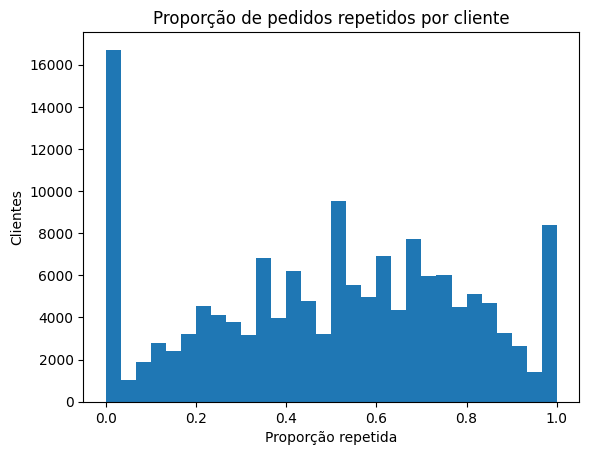

In [ ]:
clients_share_orders['reordered'].plot(kind='hist', bins=30, title='Proporção de pedidos repetidos por cliente')
plt.xlabel('Proporção repetida')
plt.ylabel('Clientes')
plt.show()

Escreva suas conclusões aqui

Podemos ver que o número de clientes que não recompram, é muito alto, mais que o dobro dos que recompraram 100% das vezes

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [ ]:

first_itens_ordered = order_products.query('add_to_cart_order == 1')['product_id'].value_counts().reset_index()
first_itens_ordered.columns = ['product_id','quantidade']
print(first_itens_ordered)


       product_id  quantidade
0           24852       15562
1           13176       11026
2           27845        4363
3           21137        3946
4           47209        3390
...           ...         ...
26755       10628           1
26756        8581           1
26757       35216           1
26758       43412           1
26759        4094           1

[26760 rows x 2 columns]


In [ ]:
name_first_itens_ordered = first_itens_ordered.merge(products, on = 'product_id')
print(name_first_itens_ordered[['product_id','product_name', 'quantidade']].head(20))

    product_id                 product_name  quantidade
0        24852                       Banana       15562
1        13176       Bag of Organic Bananas       11026
2        27845           Organic Whole Milk        4363
3        21137         Organic Strawberries        3946
4        47209         Organic Hass Avocado        3390
5        21903         Organic Baby Spinach        3336
6        47766              Organic Avocado        3044
7        19660                 Spring Water        2336
8        16797                 Strawberries        2308
9        27966          Organic Raspberries        2024
10       44632   Sparkling Water Grapefruit        1914
11       49235          Organic Half & Half        1797
12       47626                  Large Lemon        1737
13         196                         Soda        1733
14       38689     Organic Reduced Fat Milk        1397
15       26209                        Limes        1370
16       12341                Hass Avocados     

Escreva suas conclusões aqui
Novamente podemos observar apenas produtos relacionados a comida e a grande diferença das bananas que são os itens mais comprados. Podemos ver também que itens frescos geralmente são colocados primeiro nos carrinhos

# Conclusão geral do projeto:

Percebemos uma tendência por compra maior nos 2 primeiros dias da semana (domingo e segunda), e uma alta demanda por produtos orgânicos no geral. Vimos também que a média por carrinho são de 10 produtos e os pedidos geralmente são feitos em horário comercial. Muitos clientes compram apenas uma vez e não recompram mais e o que recompram, em sua maioria fazem as compras mensalmente